# Фрактальные сигналы: показатель Хёрста, DFA и шумы $1/f^\beta$

Гистограмма описывает **одномерное распределение** значений ряда, но ничего не говорит о том, **в каком порядке** эти значения идут. Два ряда могут иметь одну и ту же нормальную гистограмму и при этом вести себя совершенно по-разному: один — «честный» белый шум с независимыми значениями, другой — фрактальный процесс с долгой памятью, в котором за большими значениями чаще следуют большие, а средние по окну сходятся к истинному среднему гораздо медленнее, чем $1/\sqrt n$.

В этом ноутбуке:

1. генерируем фрактальный гауссовский шум (fGn) с заданным показателем Хёрста $H$ и шумы со спектром $1/f^\beta$: белый ($\beta=0$), розовый ($\beta=1$), коричневый ($\beta=2$);
2. разбираем по шагам метод **DFA** (*detrended fluctuation analysis*) и проверяем, что он восстанавливает $H$;
3. показываем на модели, что **нормальное распределение и фрактальный процесс неразличимы по гистограмме** — и перечисляем инструменты, которые разницу видят;
4. смотрим на практическое следствие: стандартный доверительный интервал для среднего на фрактальных данных систематически врёт.

## Немного теории

**Показатель Хёрста** $H\in(0,1)$ описывает, как растёт размах накопленного процесса с масштабом. Для **фрактального броуновского движения** (fBm) $B_H(t)$:

$$\operatorname{Var}\bigl[B_H(t+s)-B_H(t)\bigr]=\sigma^2 s^{2H}.$$

Его приращения — **фрактальный гауссовский шум** (fGn) $X_k=B_H(k+1)-B_H(k)$ — стационарны, имеют нормальное распределение $N(0,\sigma^2)$ и автокорреляцию

$$\rho(k)=\tfrac12\bigl(|k+1|^{2H}-2|k|^{2H}+|k-1|^{2H}\bigr)\;\sim\;H(2H-1)\,k^{2H-2},\quad k\to\infty.$$

- $H=0.5$ — корреляций нет, это обычный белый шум;
- $H>0.5$ — **персистентность**: положительные корреляции, убывающие *степенным образом* (долгая память);
- $H<0.5$ — **антиперсистентность**: за ростом чаще следует спад.

**Спектральная плотность** fGn на низких частотах ведёт себя как $S(f)\propto 1/f^{\beta}$ с $\beta=2H-1$, а у fBm $\beta=2H+1$.

**DFA** оценивает показатель масштабирования $\alpha$:

1. строим профиль $Y(i)=\sum_{k\le i}(x_k-\bar x)$;
2. делим профиль на окна длины $s$ и в каждом вычитаем линейный тренд;
3. считаем среднеквадратичный остаток $F(s)$;
4. повторяем для разных $s$; если $F(s)\propto s^{\alpha}$, то $\alpha$ — наклон в осях log–log.

Связь показателей:

| Сигнал | Спектр $1/f^\beta$ | DFA $\alpha$ | Хёрст |
|---|---|---|---|
| белый шум | $\beta = 0$ | $0.5$ | $H=0.5$ (fGn) |
| fGn | $\beta = 2H-1$ | $\alpha = H$ | $H$ |
| розовый шум $1/f$ | $\beta = 1$ | $1.0$ | граница стационарности |
| коричневый шум $1/f^2$ (случайное блуждание) | $\beta = 2$ | $1.5$ | fBm с $H=0.5$ |
| fBm | $\beta = 2H+1$ | $\alpha = H+1$ | $H$ |

Общая формула: $\alpha=(\beta+1)/2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats, signal

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.titleweight': 'bold',
    'axes.titlesize': 11,
    'legend.frameon': True,
    'legend.framealpha': 0.85,
    'legend.edgecolor': 'none',
    'legend.fontsize': 9,
    'lines.linewidth': 2,
})

# Цвет закреплён за сигналом и не меняется по всему ноутбуку
COLORS = {
    'white': '#52514e',   # белый шум — нейтральный эталон (H = 0.5)
    'pink':  '#d55181',   # 1/f
    'brown': '#2a78d6',   # 1/f^2
    'anti':  '#1baf7a',   # fGn, H < 0.5
    'pers':  '#6250d6',   # fGn, H > 0.5
}
# Расходящаяся шкала для H: антиперсистентность — серый (H = 0.5) — персистентность
H_CMAP = LinearSegmentedColormap.from_list('hurst', [COLORS['anti'], '#8f8e89', COLORS['pers']])


def h_color(H):
    return H_CMAP(np.clip(H, 0, 1))


rng = np.random.default_rng(7)

## 1. Генераторы сигналов и инструменты анализа

- **fGn** генерируем точным методом **Дэвиса–Харта** (циркулянтное вложение ковариационной матрицы + БПФ): значения строго гауссовские, с точной автокорреляцией $\rho(k)$.
- **Шум $1/f^\beta$** — спектральным синтезом: берём комплексный гауссовский шум в частотной области, умножаем амплитуды на $f^{-\beta/2}$, делаем обратное БПФ. Значения тоже гауссовские (линейная комбинация гауссовских величин).
- **Коричневый шум** — кумулятивная сумма белого шума (случайное блуждание).

In [2]:
def fgn(n, H, rng, sigma=1.0):
    """Фрактальный гауссовский шум длины n (метод Дэвиса–Харта)."""
    k = np.arange(n + 1)
    gamma = 0.5 * ((k + 1.0) ** (2 * H) - 2 * k ** (2 * H) + np.abs(k - 1.0) ** (2 * H))
    row = np.concatenate([gamma, gamma[-2:0:-1]])          # первая строка циркулянта, длина 2n
    m = row.size
    lam = np.fft.fft(row).real
    lam[lam < 0] = 0                                       # численный шум
    w = rng.normal(size=m) + 1j * rng.normal(size=m)
    return sigma * np.fft.fft(np.sqrt(lam / m) * w)[:n].real


def powerlaw_noise(n, beta, rng):
    """Гауссовский шум со спектром 1/f^beta (спектральный синтез), стандартизованный."""
    f = np.fft.rfftfreq(n)
    amp = np.zeros_like(f)
    amp[1:] = f[1:] ** (-beta / 2)
    spectrum = amp * (rng.normal(size=f.size) + 1j * rng.normal(size=f.size))
    x = np.fft.irfft(spectrum, n)
    return (x - x.mean()) / x.std()


def white_noise(n, rng):
    return rng.normal(size=n)


def brown_noise(n, rng):
    return np.cumsum(rng.normal(size=n))


def standardize(x):
    return (x - x.mean()) / x.std()


def dfa(x, scales, order=1):
    """DFA порядка order. Возвращает F(s) и наклон alpha в осях log-log."""
    y = np.cumsum(x - np.mean(x))
    F = np.empty(len(scales))
    for i, s in enumerate(scales):
        n_seg = len(y) // s
        segments = y[:n_seg * s].reshape(n_seg, s)
        t = np.arange(s)
        coef = np.polynomial.polynomial.polyfit(t, segments.T, order)
        trend = np.polynomial.polynomial.polyval(t, coef)
        F[i] = np.sqrt(np.mean((segments - trend) ** 2))
    alpha = np.polyfit(np.log(scales), np.log(F), 1)[0] if len(scales) > 1 else np.nan
    return F, alpha


def psd_slope(x, nperseg=1024, fmax=0.1):
    """Оценка beta по наклону спектра Уэлча на низких частотах: S(f) ~ 1/f^beta."""
    f, P = signal.welch(x, nperseg=nperseg)
    mask = (f > 0) & (f <= fmax)
    beta = -np.polyfit(np.log(f[mask]), np.log(P[mask]), 1)[0]
    return f, P, beta


def acf(x, max_lag):
    x = x - x.mean()
    full = np.correlate(x, x, mode='full')[len(x) - 1:len(x) + max_lag]
    return full / full[0]


def fgn_acf_theory(k, H):
    k = np.asarray(k, float)
    return 0.5 * (np.abs(k + 1) ** (2 * H) - 2 * np.abs(k) ** (2 * H) + np.abs(k - 1) ** (2 * H))


def log_scales(n, s_min=10, s_max_frac=8, num=20):
    return np.unique(np.logspace(np.log10(s_min), np.log10(n // s_max_frac), num).astype(int))

Проверим генератор fGn: эмпирическая автокорреляция (усреднённая по 50 реализациям) должна совпадать с теоретической $\rho(k)$.

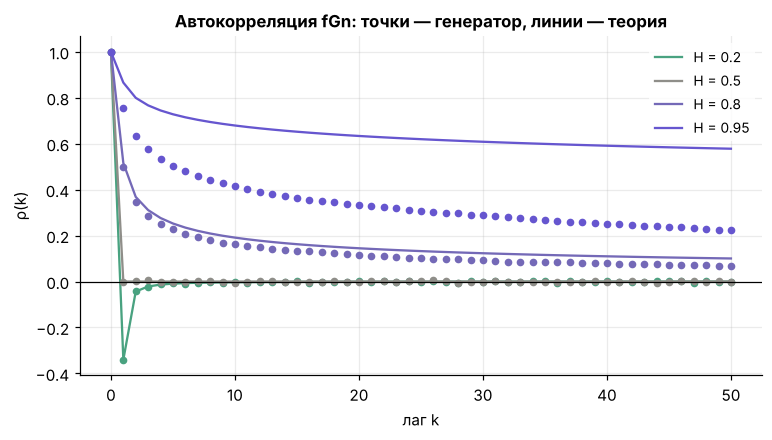

In [3]:
n = 4096
lags = np.arange(0, 51)
fig, ax = plt.subplots(figsize=(8, 4))
for H in (0.2, 0.5, 0.8, 0.95):
    emp = np.mean([acf(fgn(n, H, rng), lags[-1]) for _ in range(50)], axis=0)
    ax.plot(lags, emp, 'o', color=h_color(H), ms=4)
    ax.plot(lags, fgn_acf_theory(lags, H), color=h_color(H), lw=1.5, label=f'H = {H}')
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('лаг k')
ax.set_ylabel('ρ(k)')
ax.set_title('Автокорреляция fGn: точки — генератор, линии — теория')
ax.legend()
plt.show()

При $H=0.95$ корреляция на лаге 50 всё ещё около 0.4 — это и есть **долгая память**: степенное, а не экспоненциальное убывание. При $H=0.2$ корреляция на лаге 1 отрицательна (антиперсистентность).

## 2. Как выглядит fGn при разных $H$

Сравним реализации fGn с $H=0.2,\ 0.5,\ 0.8$ (все с одинаковой дисперсией 1). Слева — сам шум, в центре — его накопленная сумма (fBm), справа — гистограмма значений.

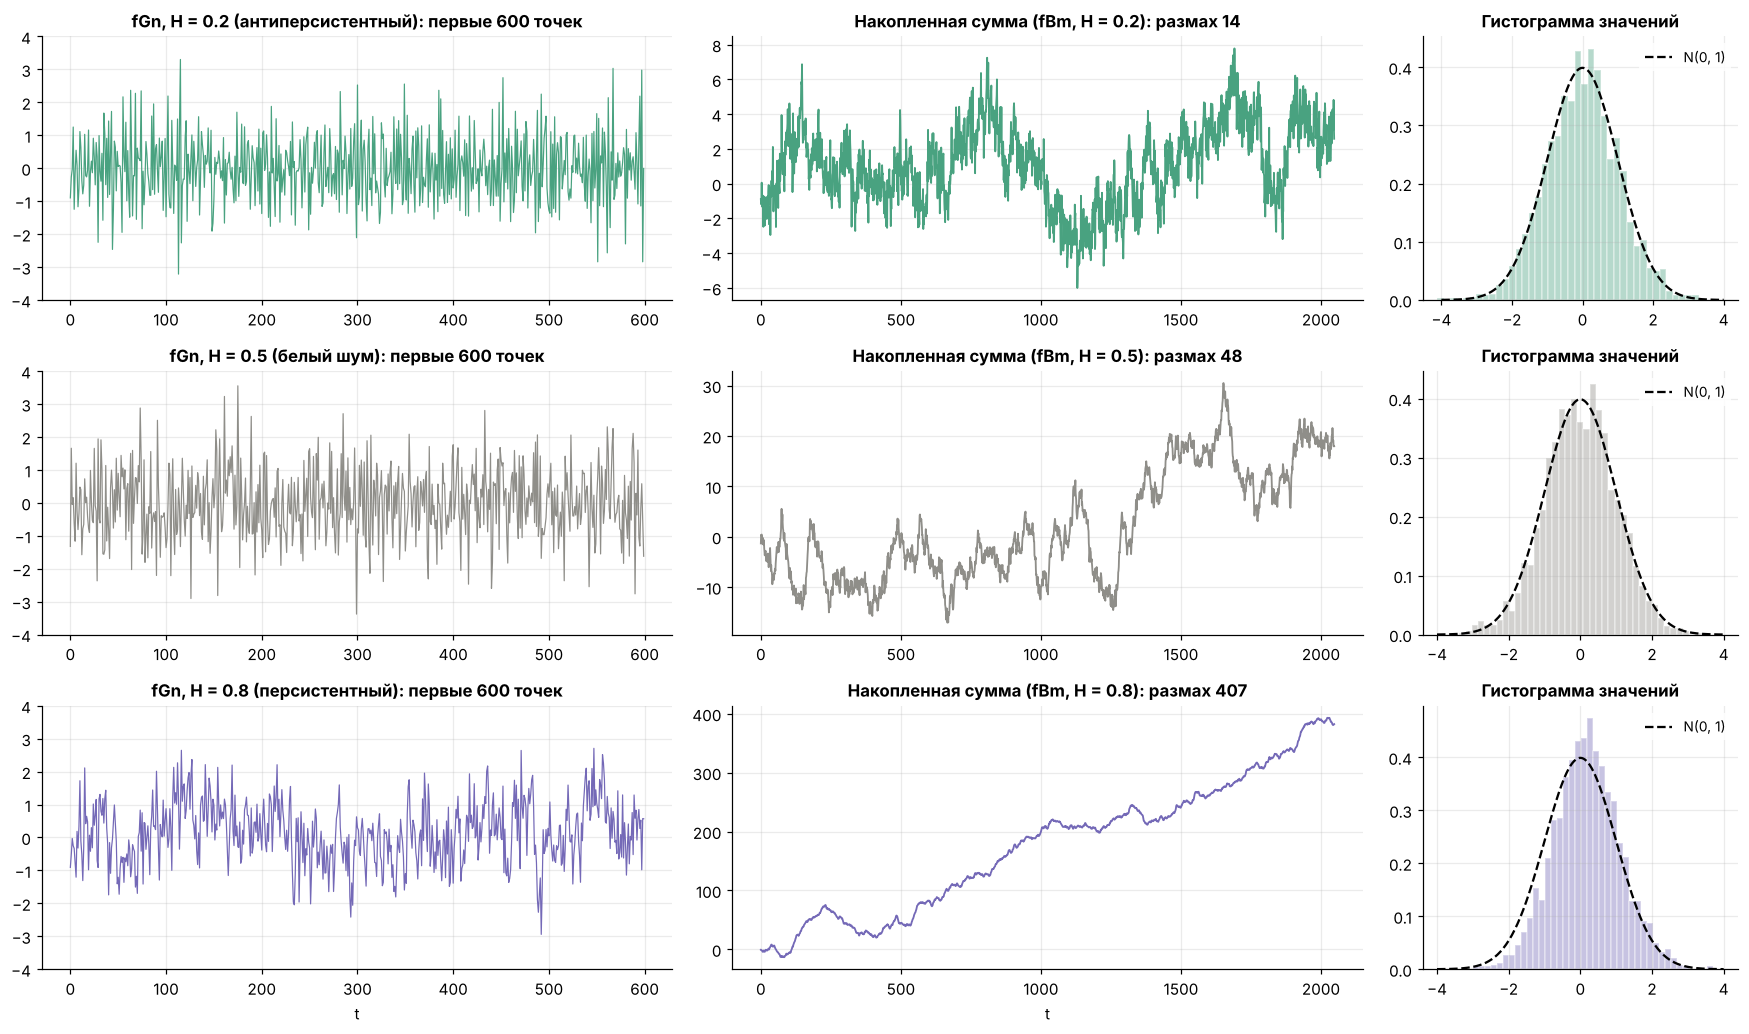

In [4]:
n = 2048
H_demo = (0.2, 0.5, 0.8)
demo = {H: fgn(n, H, rng) for H in H_demo}
names = {0.2: 'антиперсистентный', 0.5: 'белый шум', 0.8: 'персистентный'}

fig, axes = plt.subplots(3, 3, figsize=(16, 9.5), gridspec_kw={'width_ratios': [2, 2, 1]})
grid = np.linspace(-4, 4, 300)
for i, H in enumerate(H_demo):
    x, c = demo[H], h_color(H)
    axes[i, 0].plot(x[:600], color=c, lw=0.8)
    axes[i, 0].set_title(f'fGn, H = {H} ({names[H]}): первые 600 точек')
    axes[i, 0].set_ylim(-4, 4)

    cum = np.cumsum(x)
    axes[i, 1].plot(cum, color=c, lw=1.2)
    axes[i, 1].set_title(f'Накопленная сумма (fBm, H = {H}): размах {np.ptp(cum):.0f}')

    axes[i, 2].hist(x, bins=40, density=True, color=c, alpha=0.4, edgecolor='white', linewidth=1)
    axes[i, 2].plot(grid, stats.norm.pdf(grid), color='black', ls='--', lw=1.5, label='N(0, 1)')
    axes[i, 2].set_title('Гистограмма значений')
    axes[i, 2].legend(loc='upper right')
axes[-1, 0].set_xlabel('t')
axes[-1, 1].set_xlabel('t')
fig.tight_layout()
plt.show()

**Что видно:**

- Гистограммы в правой колонке практически одинаковы — во всех трёх случаях это $N(0,1)$.
- Сами ряды выглядят по-разному: при $H=0.2$ ряд «колючий», быстро меняет знак; при $H=0.8$ видны длинные участки выше и ниже нуля («волны»).
- Ещё нагляднее накопленная сумма: при $H=0.2$ она почти не уходит от нуля (отклонения гасят друг друга), при $H=0.8$ — делает большие, плавные «тренды», которых на самом деле нет: это чистый стационарный шум с долгой памятью.

## 3. Опорные сигналы: белый, розовый и коричневый шум

Теперь сравним три классических шума со спектром $1/f^\beta$. Все три ряда стандартизованы.

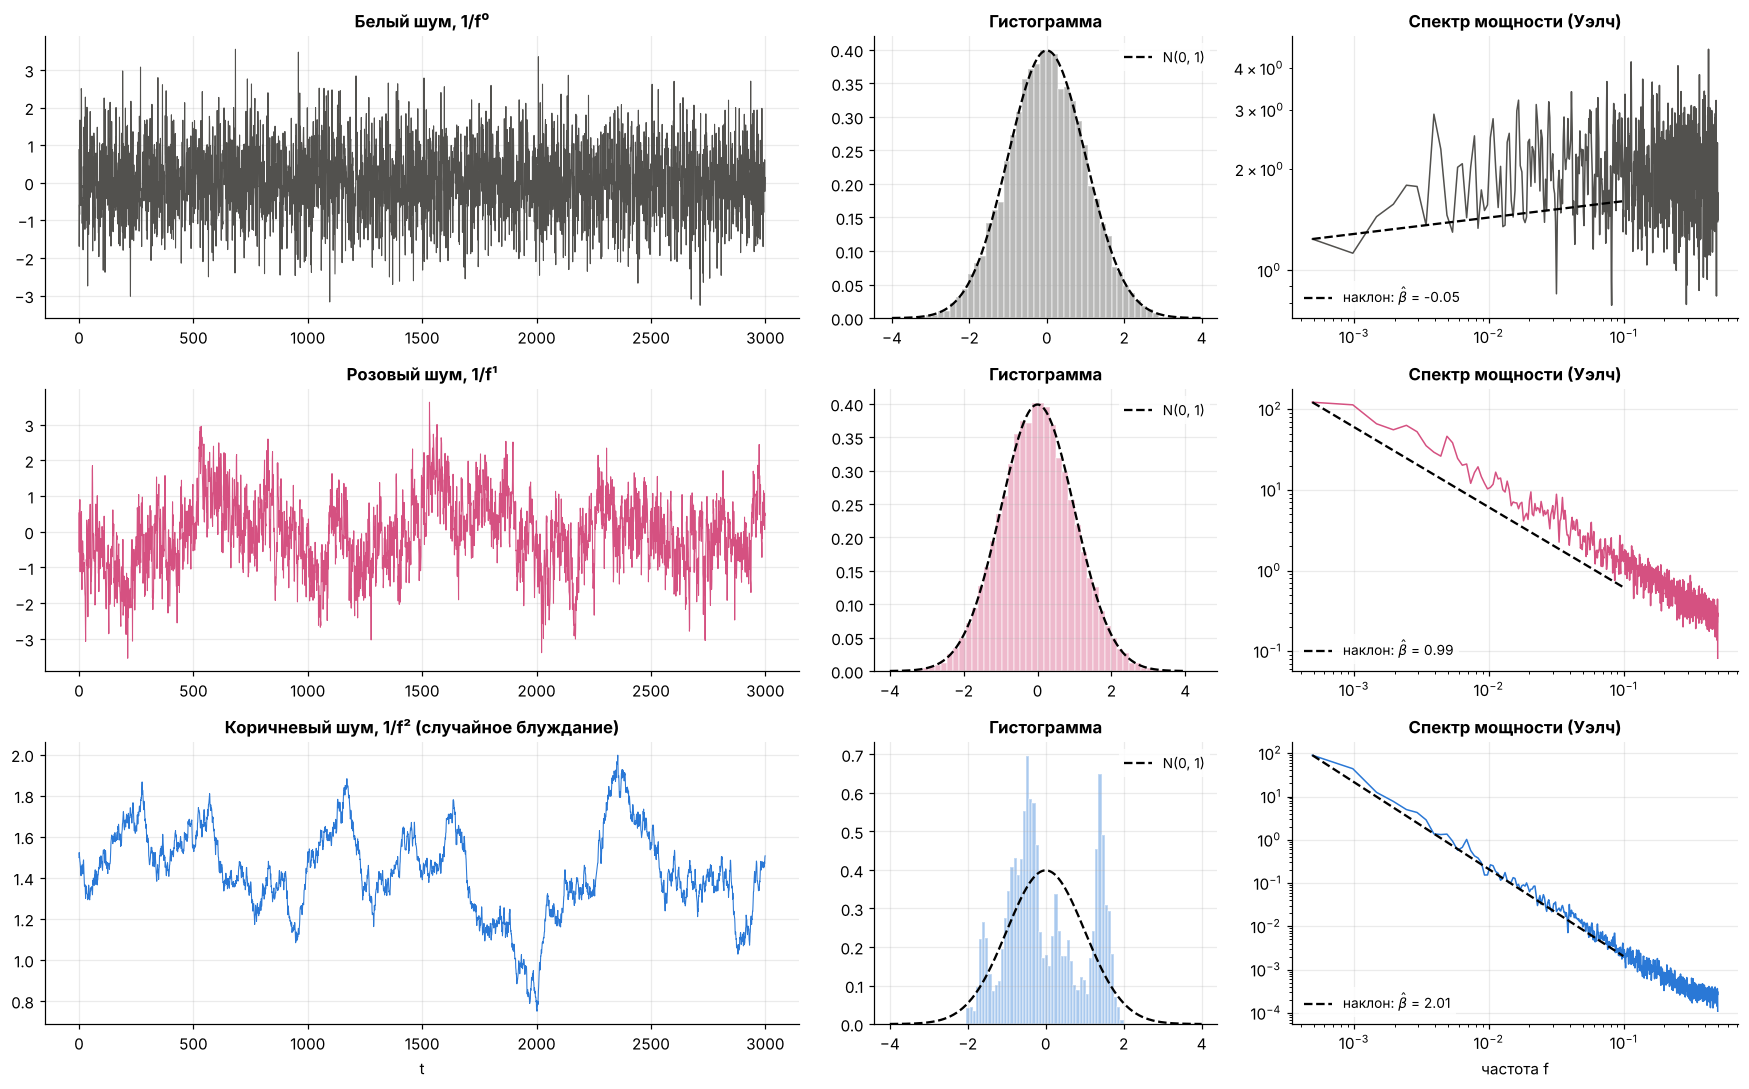

In [5]:
n = 2 ** 14
ref = {
    'white': ('Белый шум, 1/f⁰', standardize(white_noise(n, rng))),
    'pink':  ('Розовый шум, 1/f¹', powerlaw_noise(n, 1, rng)),
    'brown': ('Коричневый шум, 1/f² (случайное блуждание)', standardize(brown_noise(n, rng))),
}
scales = log_scales(n)

fig, axes = plt.subplots(3, 3, figsize=(16, 10), gridspec_kw={'width_ratios': [2.2, 1, 1.3]})
for i, (key, (title, x)) in enumerate(ref.items()):
    c = COLORS[key]
    axes[i, 0].plot(x[:3000], color=c, lw=0.7)
    axes[i, 0].set_title(title)

    axes[i, 1].hist(x, bins=50, density=True, color=c, alpha=0.4, edgecolor='white', linewidth=1)
    axes[i, 1].plot(grid, stats.norm.pdf(grid), color='black', ls='--', lw=1.5, label='N(0, 1)')
    axes[i, 1].set_title('Гистограмма')
    axes[i, 1].legend(loc='upper right')

    f, P, beta = psd_slope(x, nperseg=2048)
    axes[i, 2].loglog(f[1:], P[1:], color=c, lw=1)
    fit_f = f[(f > 0) & (f <= 0.1)]
    axes[i, 2].loglog(fit_f, P[1] * (fit_f / f[1]) ** (-beta), color='black', ls='--', lw=1.5,
                      label=rf'наклон: $\hat\beta$ = {beta:.2f}')
    axes[i, 2].set_title('Спектр мощности (Уэлч)')
    axes[i, 2].legend(loc='lower left')
axes[-1, 0].set_xlabel('t')
axes[-1, 2].set_xlabel('частота f')
fig.tight_layout()
plt.show()

Гистограммы белого и розового шума почти одинаковые; у коричневого гистограмма зависит от того, куда «забрело» блуждание (подробнее — в разделе 7). А вот **спектр** однозначно разделяет сигналы: в осях log–log это прямые с наклонами $0,\ -1,\ -2$.

Теперь DFA для этих трёх шумов и для fGn с $H=0.2$ и $H=0.8$ — на одном графике.

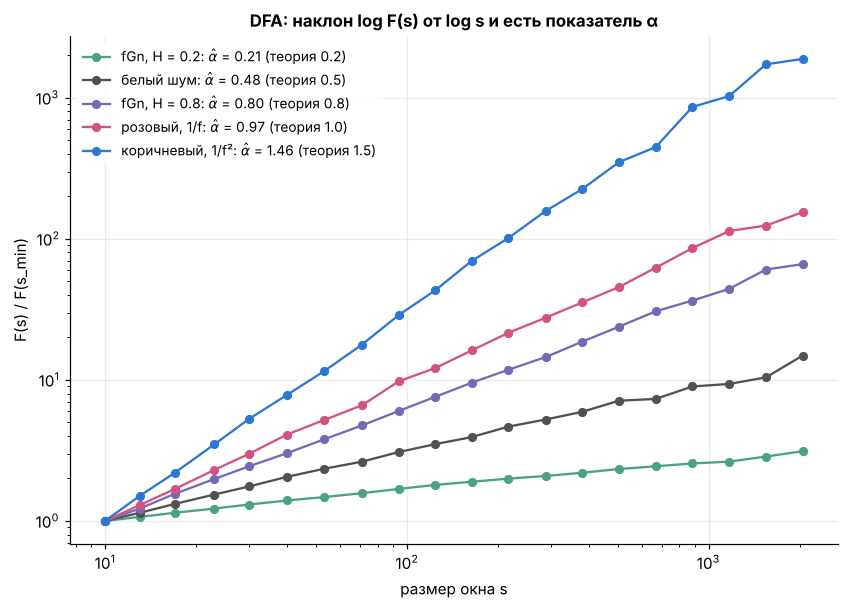

In [6]:
dfa_signals = {
    'fGn, H = 0.2':  (fgn(n, 0.2, rng), h_color(0.2), 0.2),
    'белый шум':     (ref['white'][1], COLORS['white'], 0.5),
    'fGn, H = 0.8':  (fgn(n, 0.8, rng), h_color(0.8), 0.8),
    'розовый, 1/f':  (ref['pink'][1], COLORS['pink'], 1.0),
    'коричневый, 1/f²': (ref['brown'][1], COLORS['brown'], 1.5),
}

fig, ax = plt.subplots(figsize=(9, 6))
for name, (x, c, alpha_theory) in dfa_signals.items():
    F, alpha = dfa(x, scales)
    F = F / F[0]                                  # нормируем, чтобы прямые начинались в одной точке
    ax.loglog(scales, F, 'o-', color=c, ms=5, lw=1.5,
              label=rf'{name}: $\hat\alpha$ = {alpha:.2f} (теория {alpha_theory})')
ax.set_xlabel('размер окна s')
ax.set_ylabel('F(s) / F(s_min)')
ax.set_title('DFA: наклон log F(s) от log s и есть показатель α')
ax.legend(loc='upper left')
plt.show()

## 4. DFA по шагам

Посмотрим, что именно делает DFA, на одной реализации fGn с $H=0.8$:

1. **профиль** — накопленная сумма центрированного ряда;
2. профиль режется на окна длины $s$, в каждом окне вычитается линейный тренд (красные отрезки);
3. $F(s)$ — среднеквадратичное отклонение профиля от этих трендов;
4. при увеличении $s$ остатки растут как $s^{\alpha}$.

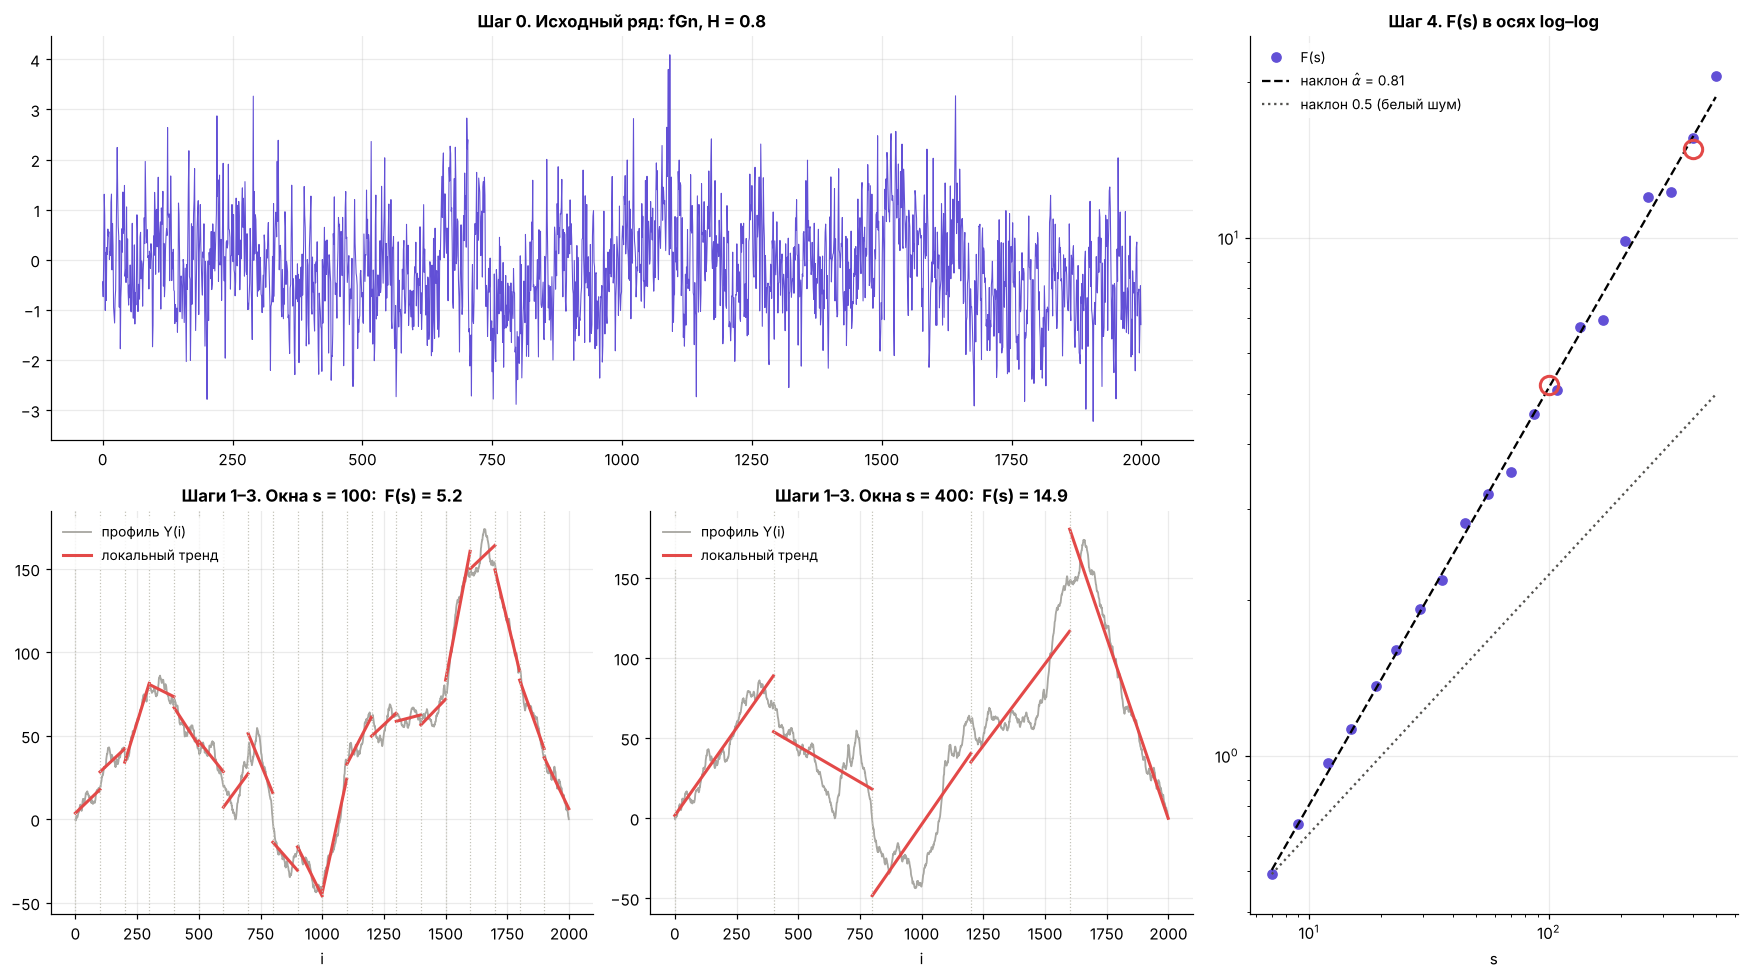

In [7]:
x = fgn(2000, 0.8, rng)
y = np.cumsum(x - x.mean())
illustr_scales = (100, 400)

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.9])

ax = fig.add_subplot(gs[0, 0:2])
ax.plot(x, color=COLORS['pers'], lw=0.7)
ax.set_title('Шаг 0. Исходный ряд: fGn, H = 0.8')

for j, s in enumerate(illustr_scales):
    ax = fig.add_subplot(gs[1, j])
    ax.plot(y, color='#a8a7a2', lw=1.2, label='профиль Y(i)')
    n_seg = len(y) // s
    for k in range(n_seg):
        t = np.arange(k * s, (k + 1) * s)
        coef = np.polyfit(t, y[t], 1)
        ax.plot(t, np.polyval(coef, t), color='#e34948', lw=2, label='локальный тренд' if k == 0 else None)
        ax.axvline(k * s, color='#c3c2b7', lw=0.8, ls=':')
    F_s = dfa(x, [s])[0][0]
    ax.set_title(f'Шаги 1–3. Окна s = {s}:  F(s) = {F_s:.1f}')
    ax.set_xlabel('i')
    ax.legend(loc='upper left')

ax = fig.add_subplot(gs[:, 2])
sc = log_scales(len(x), s_min=8, s_max_frac=4)
F, alpha = dfa(x, sc)
ax.loglog(sc, F, 'o', color=COLORS['pers'], ms=6, label='F(s)')
ax.loglog(sc, np.exp(np.polyval(np.polyfit(np.log(sc), np.log(F), 1), np.log(sc))),
          color='black', ls='--', lw=1.5, label=rf'наклон $\hat\alpha$ = {alpha:.2f}')
ax.loglog(sc, F[0] * (sc / sc[0]) ** 0.5, color=COLORS['white'], ls=':', lw=1.5,
          label='наклон 0.5 (белый шум)')
for s in illustr_scales:
    ax.loglog(s, dfa(x, [s])[0][0], 'o', ms=12, mfc='none', mec='#e34948', mew=2)
ax.set_title('Шаг 4. F(s) в осях log–log')
ax.set_xlabel('s')
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()

## 5. DFA и спектр как функции показателя Хёрста

Насколько хорошо DFA и наклон спектра восстанавливают $H$? Для сетки $H$ от 0.05 до 0.95 сгенерируем по 30 реализаций fGn длины $2^{13}$ и оценим $\hat\alpha$ и $\hat\beta$. Горизонтальными линиями отмечены значения для опорных шумов.

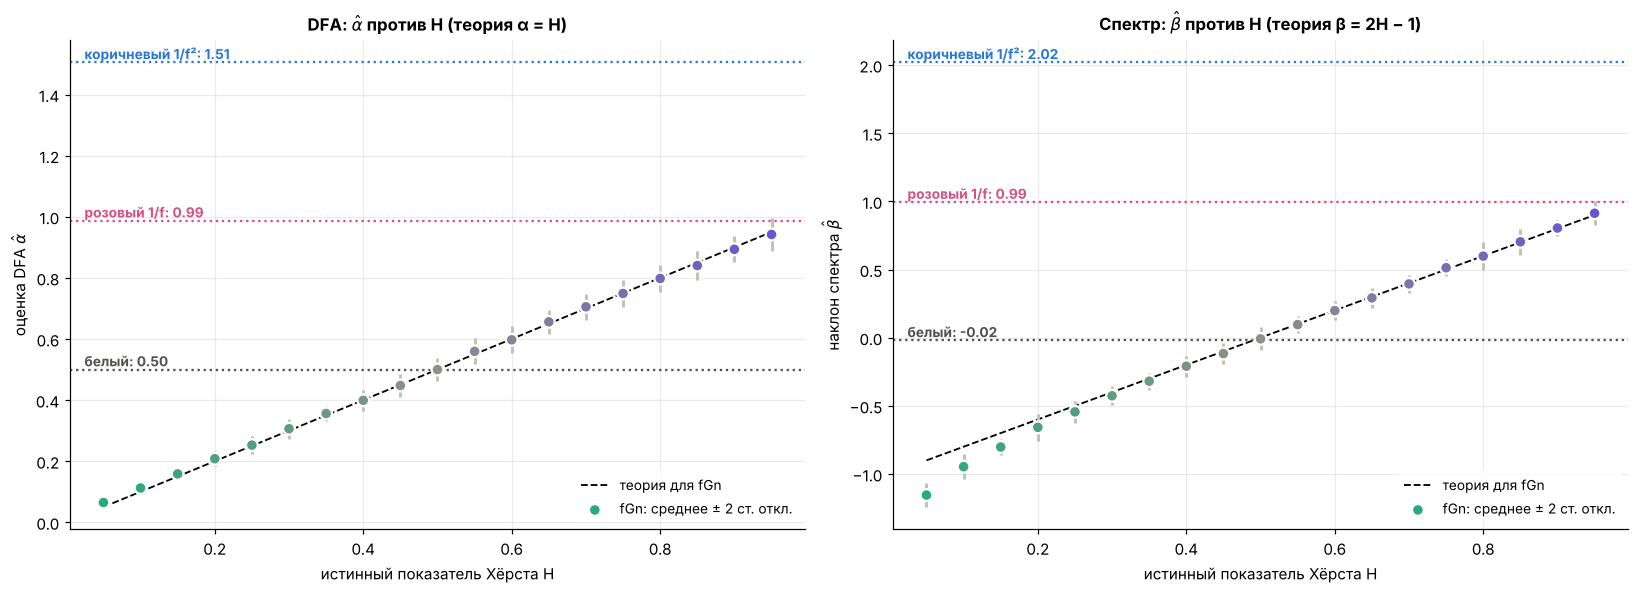

In [8]:
H_grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
n, n_rep = 2 ** 13, 30
scales = log_scales(n)

alpha_est = np.array([[dfa(fgn(n, H, rng), scales)[1] for _ in range(n_rep)] for H in H_grid])
beta_est = np.array([[psd_slope(fgn(n, H, rng))[2] for _ in range(n_rep)] for H in H_grid])

ref_alpha = {
    'white': np.mean([dfa(white_noise(n, rng), scales)[1] for _ in range(n_rep)]),
    'pink':  np.mean([dfa(powerlaw_noise(n, 1, rng), scales)[1] for _ in range(n_rep)]),
    'brown': np.mean([dfa(brown_noise(n, rng), scales)[1] for _ in range(n_rep)]),
}
ref_beta = {
    'white': np.mean([psd_slope(white_noise(n, rng))[2] for _ in range(n_rep)]),
    'pink':  np.mean([psd_slope(powerlaw_noise(n, 1, rng))[2] for _ in range(n_rep)]),
    'brown': np.mean([psd_slope(brown_noise(n, rng))[2] for _ in range(n_rep)]),
}
ref_names = {'white': 'белый', 'pink': 'розовый 1/f', 'brown': 'коричневый 1/f²'}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, est, theory, ref_vals, ylabel, title in [
        (axes[0], alpha_est, H_grid, ref_alpha, r'оценка DFA $\hat\alpha$', r'DFA: $\hat\alpha$ против H (теория α = H)'),
        (axes[1], beta_est, 2 * H_grid - 1, ref_beta, r'наклон спектра $\hat\beta$',
         r'Спектр: $\hat\beta$ против H (теория β = 2H − 1)')]:
    ax.plot(H_grid, theory, color='black', ls='--', lw=1.2, label='теория для fGn')
    m, s = est.mean(axis=1), est.std(axis=1)
    ax.errorbar(H_grid, m, yerr=2 * s, fmt='none', ecolor='#c3c2b7', elinewidth=2, capsize=0)
    ax.scatter(H_grid, m, c=[h_color(H) for H in H_grid], s=60, edgecolor='white', linewidth=1.5, zorder=3,
               label='fGn: среднее ± 2 ст. откл.')
    for key, val in ref_vals.items():
        ax.axhline(val, color=COLORS[key], lw=1.5, ls=':')
        ax.text(0.02, val, f' {ref_names[key]}: {val:.2f}', color=COLORS[key], va='bottom', fontsize=9,
                fontweight='bold')
    ax.set_xlabel('истинный показатель Хёрста H')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(loc='lower right')
fig.tight_layout()
plt.show()

**Что видно:**

- DFA восстанавливает $H$ почти без смещения во всём диапазоне; разброс растёт с $H$ (чем сильнее память, тем меньше «эффективных» независимых наблюдений).
- Наклон спектра тоже следует $\beta=2H-1$, но с бо́льшим разбросом и смещением на краях — DFA обычно надёжнее на коротких рядах.
- На одной шкале $\alpha$ укладываются все сигналы: $\alpha<0.5$ — антиперсистентный шум, $0.5$ — белый, $0.5<\alpha<1$ — стационарный шум с долгой памятью, $\approx1$ — розовый ($1/f$), $\approx1.5$ — коричневый (броуновское блуждание). Значения $\alpha>1$ означают **нестационарный** процесс.

## 6. Нормальное распределение против фрактального: одинаковые гистограммы, разные процессы

Главный вопрос: можно ли по выборке значений отличить белый гауссовский шум от фрактального гауссовского процесса? Возьмём три ряда одной длины, стандартизуем их и сравним **только распределения значений**.

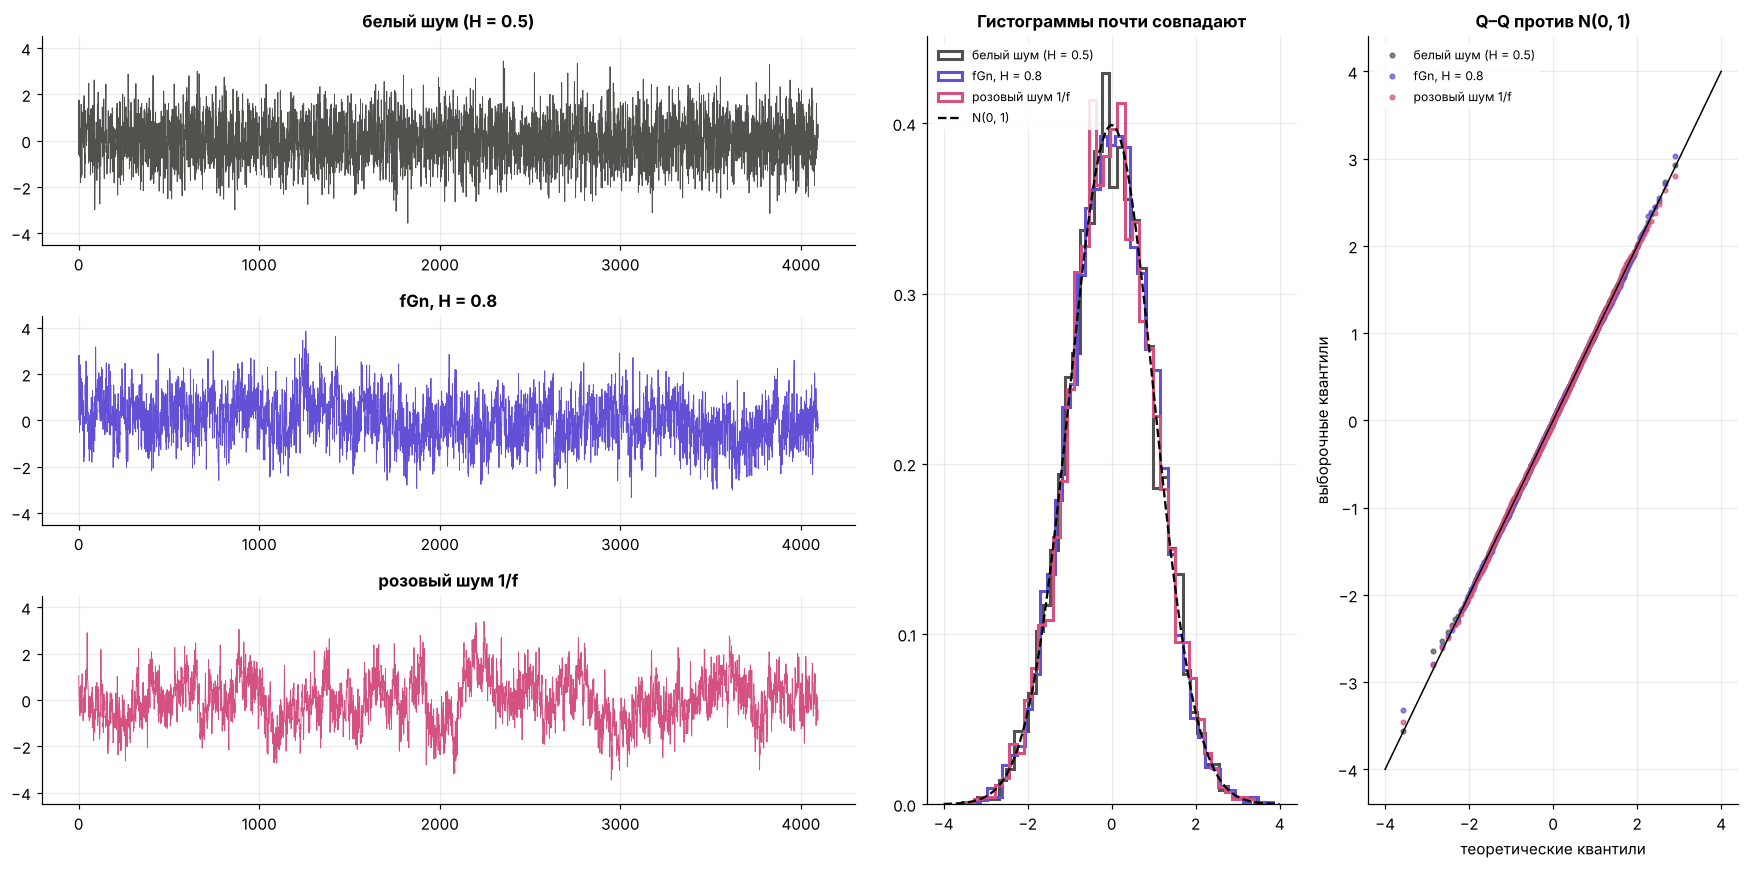

                        асимметрия   эксцесс  KS p-value   |    ρ(1)    DFA α       β
белый шум (H = 0.5)          0.028    -0.080       0.906   |   0.019     0.50    0.02
fGn, H = 0.8                 0.023    -0.006       0.982   |   0.497     0.81    0.57
розовый шум 1/f              0.007    -0.066       0.805   |   0.776     1.06    1.03


In [9]:
n = 4096
same = {
    'белый шум (H = 0.5)': (standardize(white_noise(n, rng)), COLORS['white']),
    'fGn, H = 0.8':        (standardize(fgn(n, 0.8, rng)), COLORS['pers']),
    'розовый шум 1/f':     (powerlaw_noise(n, 1, rng), COLORS['pink']),
}

fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(3, 3, width_ratios=[2.2, 1, 1])
ax_hist = fig.add_subplot(gs[:, 1])
ax_qq = fig.add_subplot(gs[:, 2])
for i, (name, (x, c)) in enumerate(same.items()):
    ax = fig.add_subplot(gs[i, 0])
    ax.plot(x, color=c, lw=0.6)
    ax.set_title(name)
    ax.set_ylim(-4.5, 4.5)
    ax_hist.hist(x, bins=40, density=True, histtype='step', color=c, lw=2, label=name)
    (osm, osr), _ = stats.probplot(x, dist='norm')
    ax_qq.plot(osm[::8], osr[::8], 'o', color=c, ms=3, alpha=0.7, label=name)
ax_hist.plot(grid, stats.norm.pdf(grid), color='black', ls='--', lw=1.5, label='N(0, 1)')
ax_hist.set_title('Гистограммы почти совпадают')
ax_hist.legend(loc='upper left', fontsize=8)
ax_qq.plot([-4, 4], [-4, 4], color='black', lw=1)
ax_qq.set_title('Q–Q против N(0, 1)')
ax_qq.set_xlabel('теоретические квантили')
ax_qq.set_ylabel('выборочные квантили')
ax_qq.legend(loc='upper left', fontsize=8)
fig.tight_layout()
plt.show()

print(f'{"":22s}{"асимметрия":>12s}{"эксцесс":>10s}{"KS p-value":>12s}   |{"ρ(1)":>8s}{"DFA α":>9s}{"β":>8s}')
for name, (x, c) in same.items():
    print(f'{name:22s}{stats.skew(x):12.3f}{stats.kurtosis(x):10.3f}{stats.kstest(x, "norm").pvalue:12.3f}   |'
          f'{acf(x, 1)[1]:8.3f}{dfa(x, log_scales(n))[1]:9.2f}{psd_slope(x)[2]:8.2f}')

**Левая часть таблицы** — то, что видит «одномерная» статистика: асимметрия и эксцесс около нуля, тест Колмогорова–Смирнова нормальность не отвергает. По этим характеристикам три ряда неразличимы: все они — выборки из $N(0,1)$.

**Правая часть** — характеристики **зависимости**: автокорреляция на лаге 1, показатель DFA и наклон спектра. Здесь ряды различаются радикально.

> Замечание: классические тесты нормальности (KS, Шапиро–Уилк) предполагают **независимость** наблюдений. На рядах с долгой памятью их p-value становятся нестабильными: эффективный объём выборки намного меньше $n$, и выборочная гистограмма заметно «гуляет» от реализации к реализации. Это не значит, что маргинальное распределение не нормально (оно нормально по построению), — это значит, что тест применён вне своих предпосылок.

### Как увидеть разницу

Ниже четыре диагностики, которые отличают белый шум от фрактального сигнала. Пунктирные линии с полыми маркерами — **перемешанная** (*shuffled*) копия того же ряда: значения те же самые, гистограмма идентична до последнего бина, но порядок случайный. Если диагностика у оригинала и у перемешанной копии различается, значит, в ряде есть структура, которую гистограмма не видит.

1. **Автокорреляционная функция** — у fGn она убывает степенным образом, а не обрывается после лага 0.
2. **Метод агрегированной дисперсии** — стандартное отклонение среднего по блокам длины $m$ убывает как $m^{H-1}$, а не как $m^{-1/2}$.
3. **Спектр мощности** — в осях log–log прямая с наклоном $-\beta$, а не горизонтальная линия.
4. **DFA** — наклон $\alpha$ отличается от 0.5.

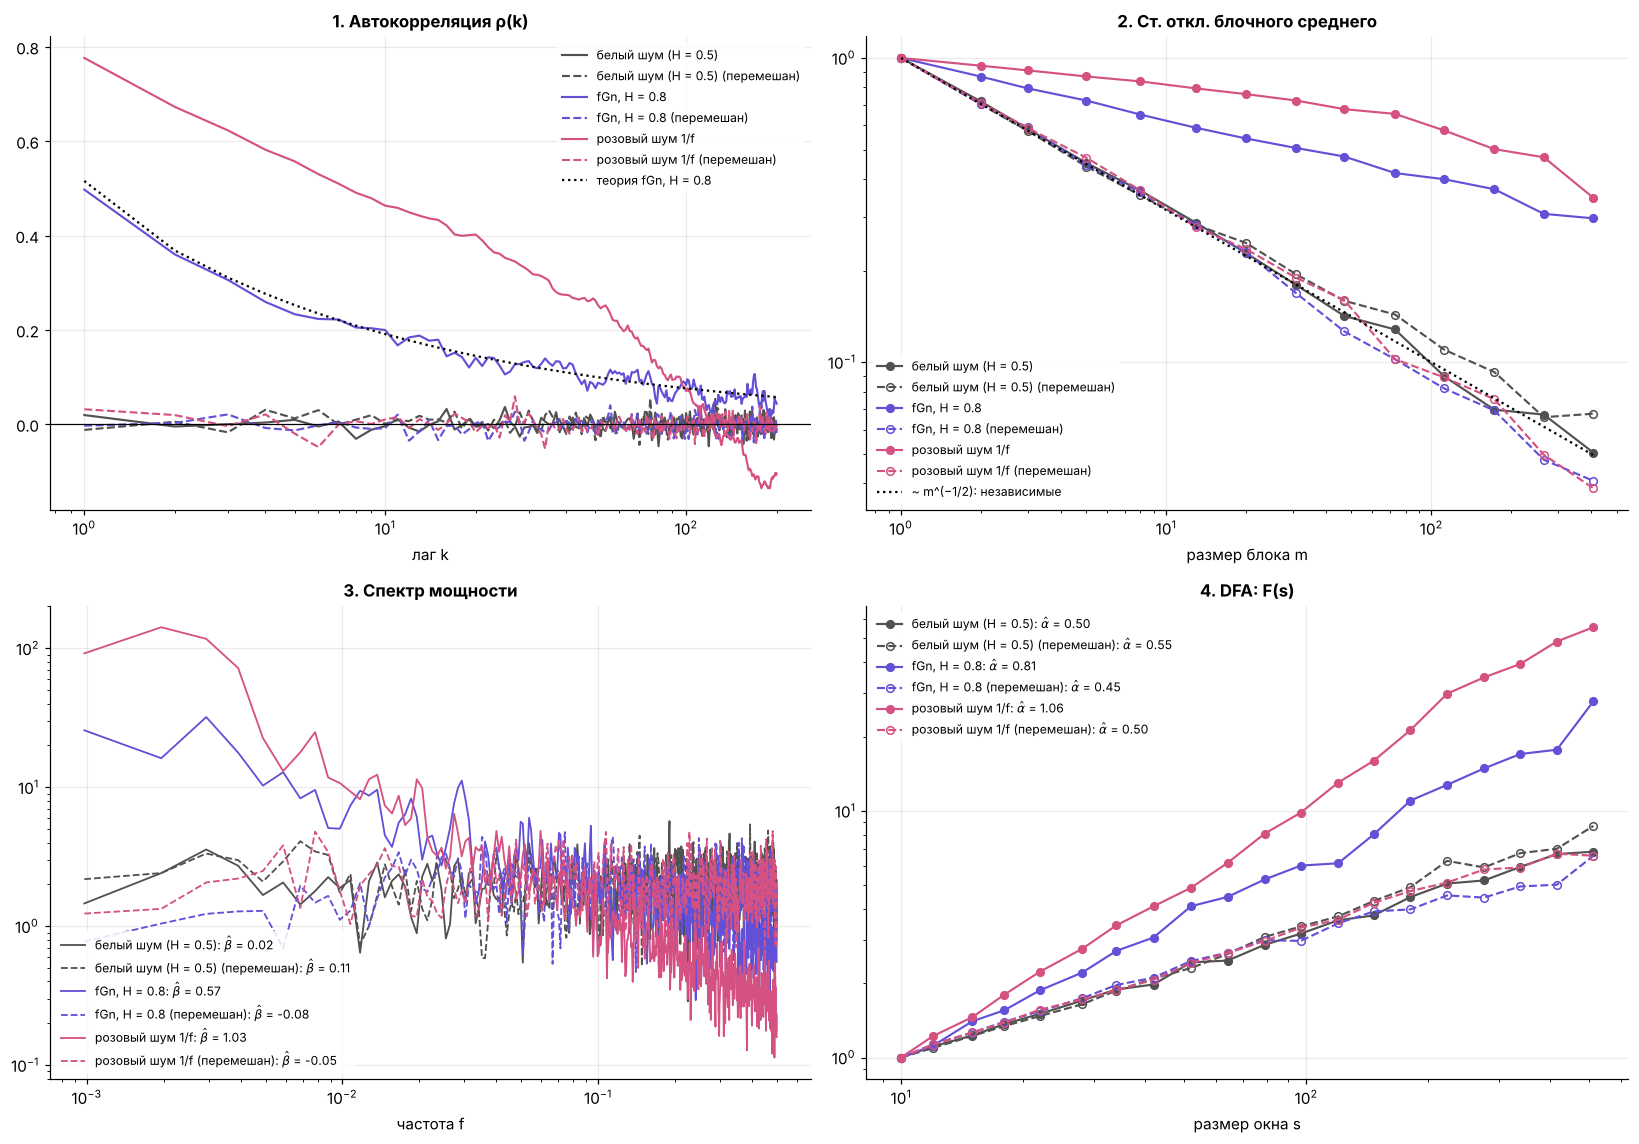

In [10]:
def block_mean_std(x, m_values):
    out = []
    for m in m_values:
        k = len(x) // m
        out.append(x[:k * m].reshape(k, m).mean(axis=1).std())
    return np.array(out)


n = len(next(iter(same.values()))[0])
lags = np.arange(1, 201)
m_values = np.unique(np.logspace(0, np.log10(n // 10), 15).astype(int))
scales = log_scales(n)

fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))
axes = axes.ravel()
for name, (x, c) in same.items():
    x_shuf = rng.permutation(x)
    for series, style, mfc, suffix in [(x, '-', c, ''), (x_shuf, '--', 'none', ' (перемешан)')]:
        lbl = name + suffix
        axes[0].plot(lags, acf(series, lags[-1])[1:], style, color=c, lw=1.4, label=lbl)
        bm = block_mean_std(series, m_values)
        axes[1].loglog(m_values, bm, style, marker='o', color=c, mfc=mfc, ms=5, lw=1.4, label=lbl)
        f, P, beta = psd_slope(series)
        axes[2].loglog(f[1:], P[1:], style, color=c, lw=1.2, label=rf'{lbl}: $\hat\beta$ = {beta:.2f}')
        F, alpha = dfa(series, scales)
        axes[3].loglog(scales, F / F[0], style, marker='o', color=c, mfc=mfc, ms=5, lw=1.4,
                       label=rf'{lbl}: $\hat\alpha$ = {alpha:.2f}')

axes[0].plot(lags, fgn_acf_theory(lags, 0.8), color='black', ls=':', lw=1.5, label='теория fGn, H = 0.8')
axes[0].axhline(0, color='black', lw=0.8)
axes[0].set_xscale('log')
axes[0].set_title('1. Автокорреляция ρ(k)')
axes[0].set_xlabel('лаг k')

axes[1].loglog(m_values, m_values ** -0.5, color='black', ls=':', lw=1.5, label='~ m^(−1/2): независимые')
axes[1].set_title('2. Ст. откл. блочного среднего')
axes[1].set_xlabel('размер блока m')

axes[2].set_title('3. Спектр мощности')
axes[2].set_xlabel('частота f')

axes[3].set_title('4. DFA: F(s)')
axes[3].set_xlabel('размер окна s')

for ax in axes:
    ax.legend(fontsize=8, loc='lower left')
axes[0].legend(fontsize=8, loc='upper right')
axes[3].legend(fontsize=8, loc='upper left')
fig.tight_layout()
plt.show()

**Что видно:**

- У белого шума оригинал и перемешанная копия ведут себя одинаково — порядок значений не несёт информации.
- У fGn и розового шума перемешивание **уничтожает** структуру: автокорреляция падает до нуля, наклон блочного среднего возвращается к $-1/2$, спектр становится плоским, а $\hat\alpha$ — равным 0.5. Гистограмма при этом не изменилась ни на йоту.
- Значит, «фрактальность» — свойство **совместного** распределения значений (порядка, зависимости), а не одномерного распределения. Фрактальный сигнал может иметь ровно нормальную гистограмму, и наоборот — нормальная гистограмма ничего не говорит о независимости.

**Суррогатный тест** (сравнение со случайно перемешанными копиями) — простой и наглядный способ формально проверить наличие долгой памяти: если $\hat\alpha$ исходного ряда лежит далеко за пределами распределения $\hat\alpha$ перемешанных копий, корреляционная структура значима.

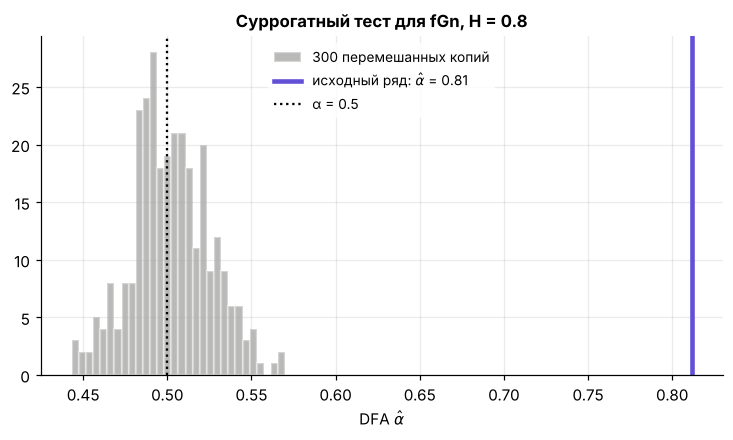

Суррогаты: α̂ = 0.502 ± 0.023;  доля суррогатов с α̂ ≥ исходного: 0.000


In [11]:
x = same['fGn, H = 0.8'][0]
alpha_orig = dfa(x, scales)[1]
alpha_surr = np.array([dfa(rng.permutation(x), scales)[1] for _ in range(300)])

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(alpha_surr, bins=30, color=COLORS['white'], alpha=0.4, edgecolor='white', linewidth=1.5,
        label='300 перемешанных копий')
ax.axvline(alpha_orig, color=COLORS['pers'], lw=3, label=rf'исходный ряд: $\hat\alpha$ = {alpha_orig:.2f}')
ax.axvline(0.5, color='black', ls=':', lw=1.5, label='α = 0.5')
ax.set_xlabel(r'DFA $\hat\alpha$')
ax.set_title('Суррогатный тест для fGn, H = 0.8')
ax.legend()
plt.show()
print(f'Суррогаты: α̂ = {alpha_surr.mean():.3f} ± {alpha_surr.std():.3f};  '
      f'доля суррогатов с α̂ ≥ исходного: {np.mean(alpha_surr >= alpha_orig):.3f}')

## 7. Почему это важно: доверительный интервал для среднего

Стандартный доверительный интервал $\bar x \pm 1.96\, s/\sqrt n$ опирается на то, что дисперсия среднего равна $\sigma^2/n$. Для fGn это не так:

$$\operatorname{Var}(\bar x)=\sigma^2 n^{2H-2},$$

т.е. при $H>0.5$ стандартная ошибка в $n^{H-1/2}$ раз **больше**, чем даёт формула. При $n=1000$ и $H=0.8$ это множитель $1000^{0.3}\approx8$.

Проверим методом Монте-Карло: сгенерируем 2000 рядов длины 1000 с истинным средним 0 и посчитаем, как часто «95%»-интервал накрывает ноль.

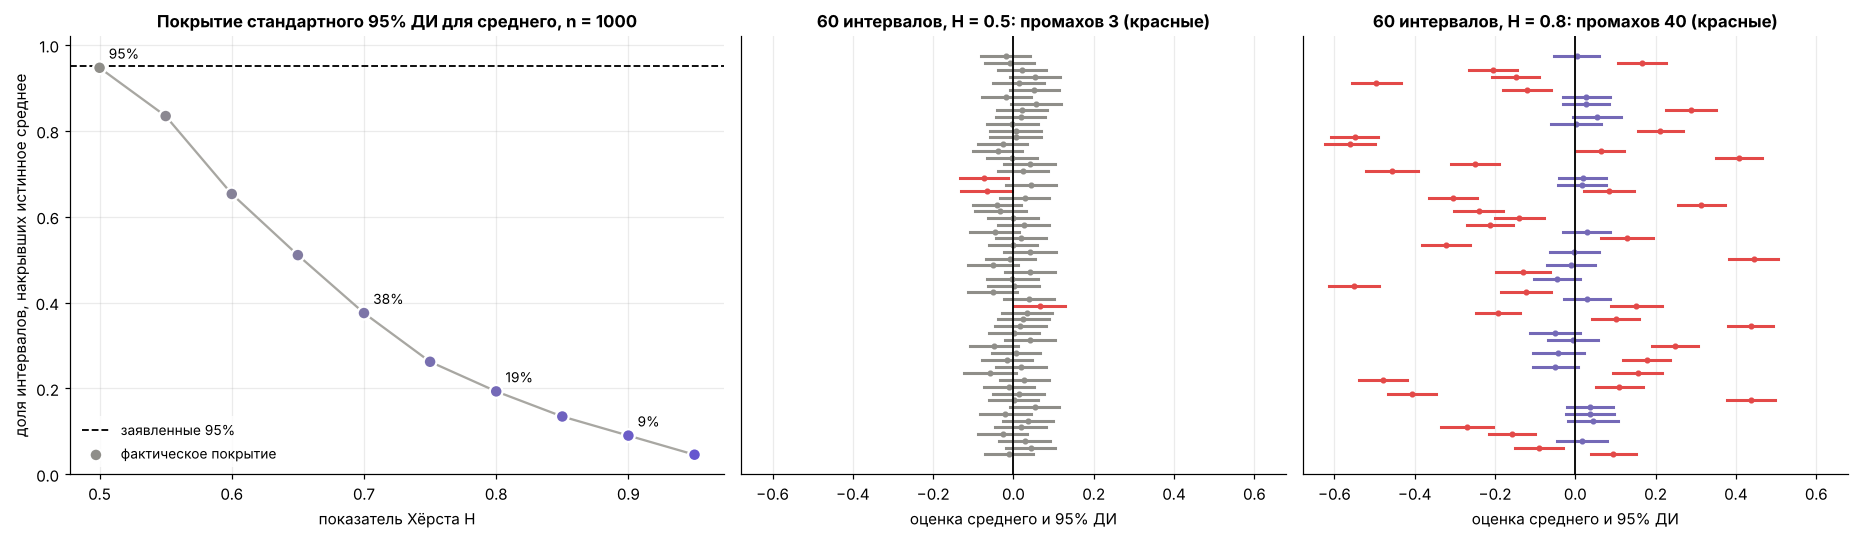

In [12]:
n, n_sim = 1000, 2000
H_cov = np.round(np.arange(0.5, 0.96, 0.05), 2)
coverage, ci_examples = [], {}
for H in H_cov:
    hits = 0
    examples = []
    for i in range(n_sim):
        x = fgn(n, H, rng)
        m, se = x.mean(), x.std(ddof=1) / np.sqrt(n)
        hits += abs(m) <= 1.96 * se
        if i < 60:
            examples.append((m, se))
    coverage.append(hits / n_sim)
    ci_examples[H] = np.array(examples)
coverage = np.array(coverage)

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={'width_ratios': [1.2, 1, 1]})
ax = axes[0]
ax.axhline(0.95, color='black', ls='--', lw=1.2, label='заявленные 95%')
ax.plot(H_cov, coverage, color='#a8a7a2', lw=1.5, zorder=1)
ax.scatter(H_cov, coverage, c=[h_color(H) for H in H_cov], s=70, edgecolor='white', linewidth=1.5, zorder=2,
           label='фактическое покрытие')
for H, cov in zip(H_cov, coverage):
    if H in (0.5, 0.7, 0.8, 0.9):
        ax.annotate(f'{cov:.0%}', (H, cov), xytext=(6, 6), textcoords='offset points', fontsize=9)
ax.set_ylim(0, 1.02)
ax.set_xlabel('показатель Хёрста H')
ax.set_ylabel('доля интервалов, накрывших истинное среднее')
ax.set_title('Покрытие стандартного 95% ДИ для среднего, n = 1000')
ax.legend(loc='lower left')

for ax, H in zip(axes[1:], (0.5, 0.8)):
    ex = ci_examples[H]
    miss = np.abs(ex[:, 0]) > 1.96 * ex[:, 1]
    for k, ((m, se), bad) in enumerate(zip(ex, miss)):
        ax.plot([m - 1.96 * se, m + 1.96 * se], [k, k], color='#e34948' if bad else h_color(H), lw=2)
        ax.plot(m, k, 'o', color='#e34948' if bad else h_color(H), ms=3)
    ax.axvline(0, color='black', lw=1.2)
    ax.set_title(f'60 интервалов, H = {H}: промахов {miss.sum()} (красные)')
    ax.set_xlabel('оценка среднего и 95% ДИ')
    ax.set_yticks([])
    ax.grid(axis='y', visible=False)
lim = max(np.abs(axes[2].get_xlim()))
for ax in axes[1:]:
    ax.set_xlim(-lim, lim)
fig.tight_layout()
plt.show()

При $H=0.5$ покрытие — честные 95%. При $H=0.8$ «95%»-интервал накрывает истинное среднее лишь примерно в каждом пятом случае: интервалы слишком узкие, а оценки среднего гуляют гораздо шире, чем предполагает формула. Если такие данные (например, поминутные метрики сервиса или ежедневные метрики пользователей с долгой памятью) анализировать как независимые, мы будем постоянно находить «значимые» эффекты там, где их нет.

## 8. Коричневый шум ($1/f^2$): у нестационарного процесса нет «своей» гистограммы

Для белого шума гистограмма любой реализации — оценка одного и того же распределения $N(0,1)$. Для случайного блуждания это не так: процесс нестационарен ($\alpha\approx1.5>1$), его дисперсия растёт со временем, и гистограммы разных реализаций **не похожи друг на друга**. Это ещё один способ «увидеть» фрактальность: сравнить гистограммы разных окон или разных реализаций.

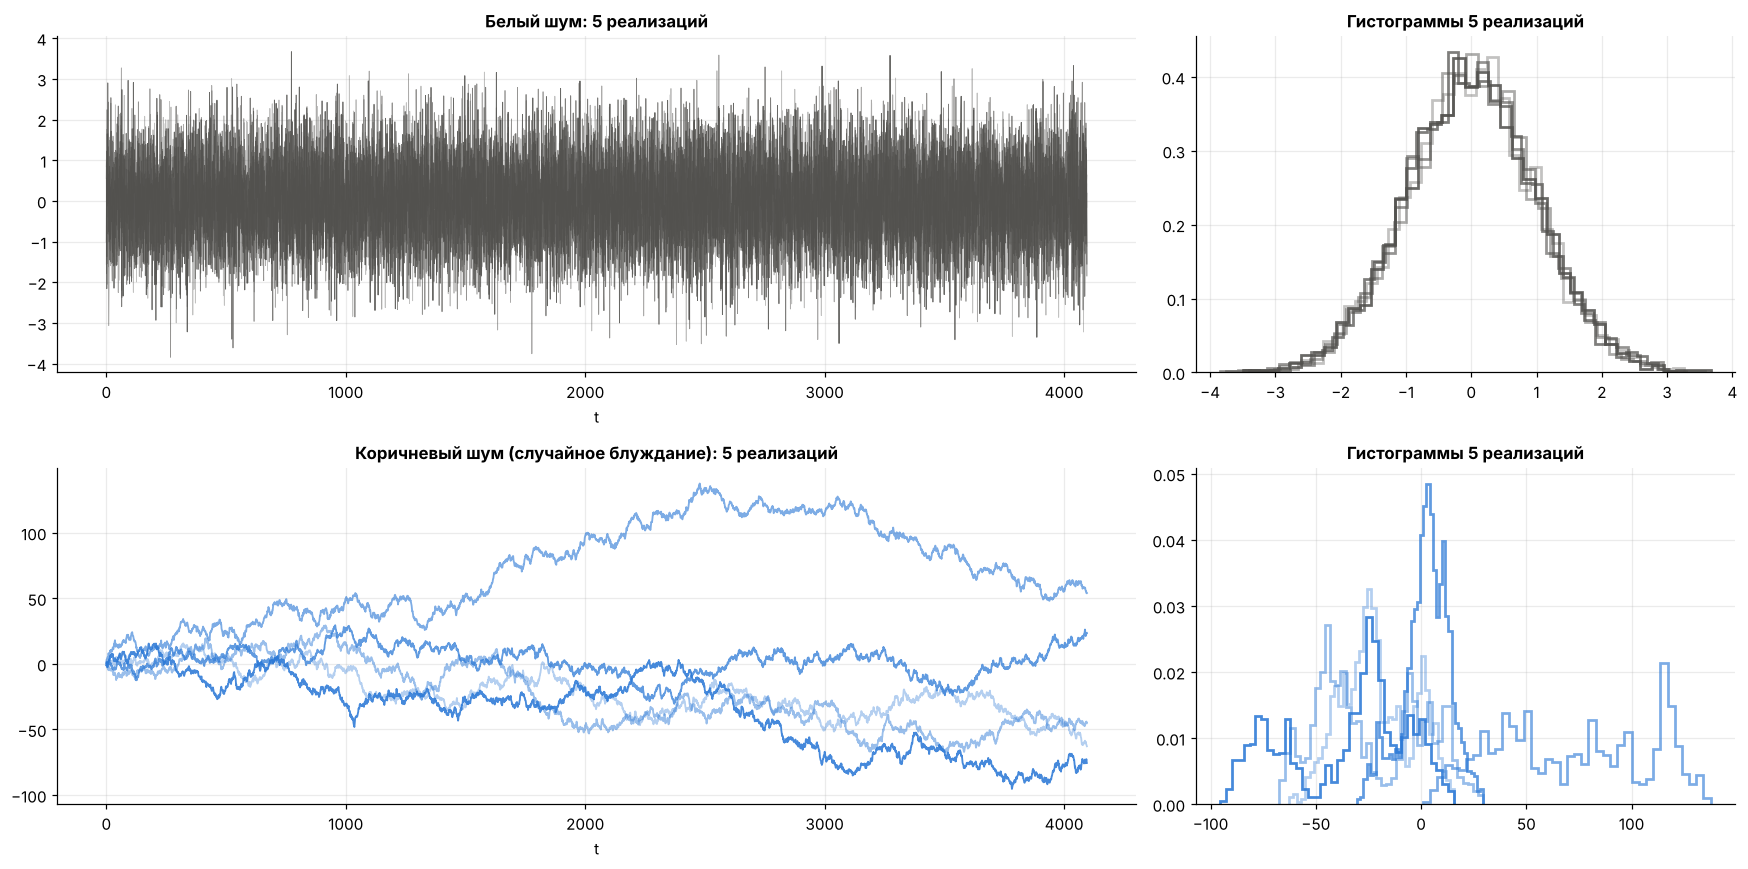

In [13]:
n = 4096
fig, axes = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw={'width_ratios': [2, 1]})
for row, (key, gen, title) in enumerate([('white', white_noise, 'Белый шум'),
                                         ('brown', brown_noise, 'Коричневый шум (случайное блуждание)')]):
    ax_ts, ax_h = axes[row]
    for r in range(5):
        x = gen(n, rng)
        shade = 0.35 + 0.13 * r
        ax_ts.plot(x, color=COLORS[key], alpha=shade, lw=0.6 if key == 'white' else 1.2)
        ax_h.hist(x, bins=40, density=True, histtype='step', color=COLORS[key], alpha=shade, lw=1.8)
    ax_ts.set_title(f'{title}: 5 реализаций')
    ax_ts.set_xlabel('t')
    ax_h.set_title('Гистограммы 5 реализаций')
fig.tight_layout()
plt.show()

## Итоги

**Нормальное (белое) и фрактальное различаются не формой гистограммы, а структурой зависимости.** Фрактальный гауссовский шум имеет ровно нормальное одномерное распределение, но значения в нём связаны степенной долгой памятью, которую описывает показатель Хёрста $H$.

| | Белый шум | fGn, $0.5<H<1$ | Розовый $1/f$ | Коричневый $1/f^2$ |
|---|---|---|---|---|
| Гистограмма | $N(0,1)$ | $N(0,1)$ | $N(0,1)$ | зависит от реализации |
| ACF | 0 при $k\ge1$ | $\sim k^{2H-2}$ | очень медленно убывает | процесс нестационарен |
| Спектр $\beta$ | 0 | $2H-1$ | 1 | 2 |
| DFA $\alpha$ | 0.5 | $H$ | 1 | 1.5 |
| Ст. ошибка среднего | $\sigma/\sqrt n$ | $\sigma\, n^{H-1}$ | — | не определена |

**Как увидеть фрактальность на практике:**

1. Не ограничиваться гистограммой и тестами нормальности: они отвечают только на вопрос о форме одномерного распределения.
2. Построить **ACF** в логарифмической шкале лагов: степенной хвост — признак долгой памяти.
3. Построить **спектр мощности** в осях log–log и оценить наклон $\beta$.
4. Посчитать **DFA** и наклон $\alpha$: $0.5$ — независимость, $0.5<\alpha<1$ — долгая память, $\alpha>1$ — нестационарность.
5. Сравнить с **перемешанными суррогатами**: если перемешивание меняет $\alpha$, ACF или спектр, структура в данных реальна.
6. Помнить о последствиях: при $H>0.5$ классические доверительные интервалы и тесты для среднего (t-test, z-test) **занижают** неопределённость и дают ложные «значимые» результаты.